<a href="https://colab.research.google.com/github/francji1/01NAEX/blob/main/code/01NAEX_Ex06.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 01NAEX - Exercise 06: A single replicate of the $2^k$ design

Data and exercises come from D. C. Montgomery: *Design and Analysis of Experiments*, 8th edition, Chapter 6
(Sections 6.5 and 6.6). Problem numbers follow the 8th edition.

## Learning goals

* Compute all $2^k - 1$ effects of an unreplicated $2^k$ design and explain why the full model has no error term.
* Identify the active effects with the normal (Daniel) and half-normal probability plots and with Lenth's method
  (pseudo standard error, margin of error, simultaneous margin of error, Pareto plot).
* Project the design onto the active factors, fit and check the final model and interpret it with contour plots.
* Recognize the effect of an outlier on the normal plot of effects.
* Use a transformation of the response (log, Box-Cox) and detect dispersion effects from the residuals.

## Setup

Run this cell first. Besides the standard imports it defines helper functions used below:

* `effects_2k()` - contrasts, effects, sums of squares and coded coefficients of a $2^k$ design (Exercise 5).
* `effect_plot()` - normal (or half-normal) probability plot of the effects with a reference line through the small effects.
* `lenth()` - Lenth's pseudo standard error $PSE$, margin of error $ME$ and simultaneous margin of error $SME$.
* `pareto_plot()` - bar chart of the absolute effects with the $ME$ and $SME$ lines.
* `residual_plots()` - normal Q-Q plot of the residuals, residuals versus fitted values and versus each factor, Shapiro-Wilk test.

In [113]:
import itertools

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy import stats
import statsmodels.api as sm
import statsmodels.formula.api as smf
from statsmodels.stats.anova import anova_lm
from statsmodels.graphics.factorplots import interaction_plot

URL = "https://raw.githubusercontent.com/francji1/01NAEX/main/data/"


def effects_2k(data, response, factors):
    """Contrasts, effects, sums of squares and coded coefficients of a balanced 2^k design.

    `factors` are columns coded -1/+1 (main effects in this order: A, B, C, ...). Rows are in standard order
    (A, B, AB, C, AC, BC, ABC, ...) and are named as in statsmodels formulas ("A:B").
    """
    k = len(factors)
    n = len(data) // 2**k
    rows = []
    for i in range(1, 2**k):
        members = [factors[j] for j in range(k) if i >> j & 1]
        sign = data[members].prod(axis=1)
        contrast = (sign * data[response]).sum()
        rows.append({"term": ":".join(members), "contrast": contrast,
                     "effect": contrast / (n * 2**(k - 1)), "SS": contrast**2 / (n * 2**k)})
    table = pd.DataFrame(rows).set_index("term")
    table["coef"] = table["effect"] / 2
    return table


def effect_plot(effects, half=False, n_label=5, ax=None, title=None):
    """Normal (Daniel) or half-normal probability plot of the effects (a pd.Series indexed by the effect names).

    The reference line is fitted to the smaller half of the effects (through the origin for the half-normal plot).
    The n_label largest effects (in absolute value) are labelled.
    """
    e = (effects.abs() if half else effects).sort_values()
    m = len(e)
    p = (np.arange(1, m + 1) - 0.5) / m
    q = stats.halfnorm.ppf(p) if half else stats.norm.ppf(p)
    x = e.to_numpy(dtype=float)
    small = np.argsort(np.abs(x))[: m // 2 + 1]
    if half:
        b, a = (x[small] @ q[small]) / (q[small] @ q[small]), 0.0
        qq = np.linspace(0, q.max(), 50)
    else:
        b, a = np.polyfit(q[small], x[small], 1)
        qq = np.linspace(q.min(), q.max(), 50)
    if ax is None:
        ax = plt.subplots(figsize=(5, 4))[1]
    ax.scatter(x, q, color="k", s=20)
    ax.plot(a + b * qq, qq, color="tab:red", lw=1)
    largest = effects.abs().sort_values().index[-n_label:] if n_label else []
    for name, xi, qi in zip(e.index, x, q):
        if name in largest:
            ax.annotate(name, (xi, qi), xytext=(4, -3), textcoords="offset points")
    ax.set_xlabel("|effect|" if half else "effect")
    ax.set_ylabel("half-normal quantile" if half else "normal quantile")
    ax.set_title(title or ("Half-normal plot of effects" if half else "Normal probability plot of effects"))
    return ax


def lenth(effects, alpha=0.05):
    """Lenth's method: s0, pseudo standard error, margin of error and simultaneous margin of error."""
    c = np.abs(np.asarray(effects, dtype=float))
    m = len(c)
    s0 = 1.5 * np.median(c)
    pse = 1.5 * np.median(c[c < 2.5 * s0])
    d = m / 3
    me = stats.t.ppf(1 - alpha / 2, d) * pse
    gamma = (1 + (1 - alpha) ** (1 / m)) / 2
    sme = stats.t.ppf(gamma, d) * pse
    return {"s0": s0, "PSE": pse, "ME": me, "SME": sme}


def pareto_plot(effects, alpha=0.05, ax=None):
    """Bars of |effect| sorted by size with Lenth's ME and SME lines."""
    L = lenth(effects, alpha)
    e = effects.abs().sort_values(ascending=False)
    if ax is None:
        ax = plt.subplots(figsize=(9, 3.5))[1]
    ax.bar(e.index, e.to_numpy(), color=np.where(e > L["ME"], "tab:blue", "lightgray"))
    ax.axhline(L["ME"], color="tab:orange", ls="--", label=f"ME = {L['ME']:.2f}")
    ax.axhline(L["SME"], color="tab:red", ls="--", label=f"SME = {L['SME']:.2f}")
    ax.set_ylabel("|effect|")
    ax.tick_params(axis="x", rotation=90)
    ax.legend()
    ax.set_title("Pareto plot of the effects (Lenth)")
    return ax


def residual_plots(model, data, factors):
    """Q-Q plot, residuals vs fitted values and vs each factor; Shapiro-Wilk test of the residuals."""
    res, fit = model.resid, model.fittedvalues
    fig, axes = plt.subplots(1, 2 + len(factors), figsize=(3.3 * (2 + len(factors)), 3.2))
    sm.qqplot(res, line="s", ax=axes[0])
    axes[0].set_title("Normal Q-Q plot")
    axes[1].scatter(fit, res)
    axes[1].axhline(0, color="red", ls="--")
    axes[1].set(xlabel="fitted", ylabel="residual", title="Residuals vs fitted")
    for ax, f in zip(axes[2:], factors):
        ax.scatter(data[f], res)
        ax.axhline(0, color="red", ls="--")
        ax.set(xlabel=f, title=f"Residuals vs {f}")
    plt.tight_layout()
    plt.show()
    print("Shapiro-Wilk on residuals:", stats.shapiro(res))

## 1. Lecture example: filtration rate ($2^4$ design, a single replicate)

Montgomery, Example 6.2: the filtration rate (gal/h) of a resin in a pilot plant. Four factors: $A$ temperature,
$B$ pressure, $C$ concentration of formaldehyde, $D$ stirring rate. One replicate of the $2^4$ design, the 16 runs in random
order. The aim is to **maximize** the filtration rate. The file lists the runs in standard order.

In [114]:
rate = pd.read_csv(URL + "Pilot_Plant_Filtration_Rate_Experiment.csv", sep=";")
factors = list("ABCD")
rate["label"] = ["".join(f.lower() for f in factors if r[f] == 1) or "(1)" for _, r in rate.iterrows()]
rate

,A,B,C,D,Rate,label
0,-1,-1,-1,-1,45,(1)
1,1,-1,-1,-1,71,a
2,-1,1,-1,-1,48,b
3,1,1,-1,-1,65,ab
4,-1,-1,1,-1,68,c
5,1,-1,1,-1,60,ac
6,-1,1,1,-1,80,bc
7,1,1,1,-1,65,abc
8,-1,-1,-1,1,43,d
9,1,-1,-1,1,100,ad


### Main effects and interaction plots

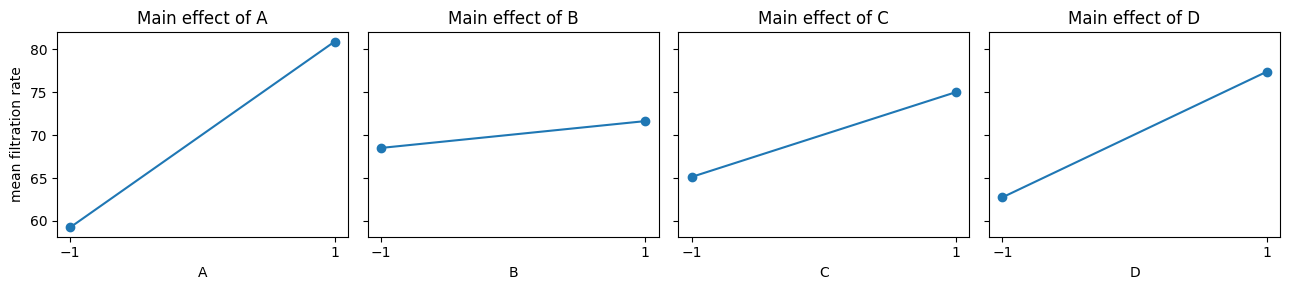

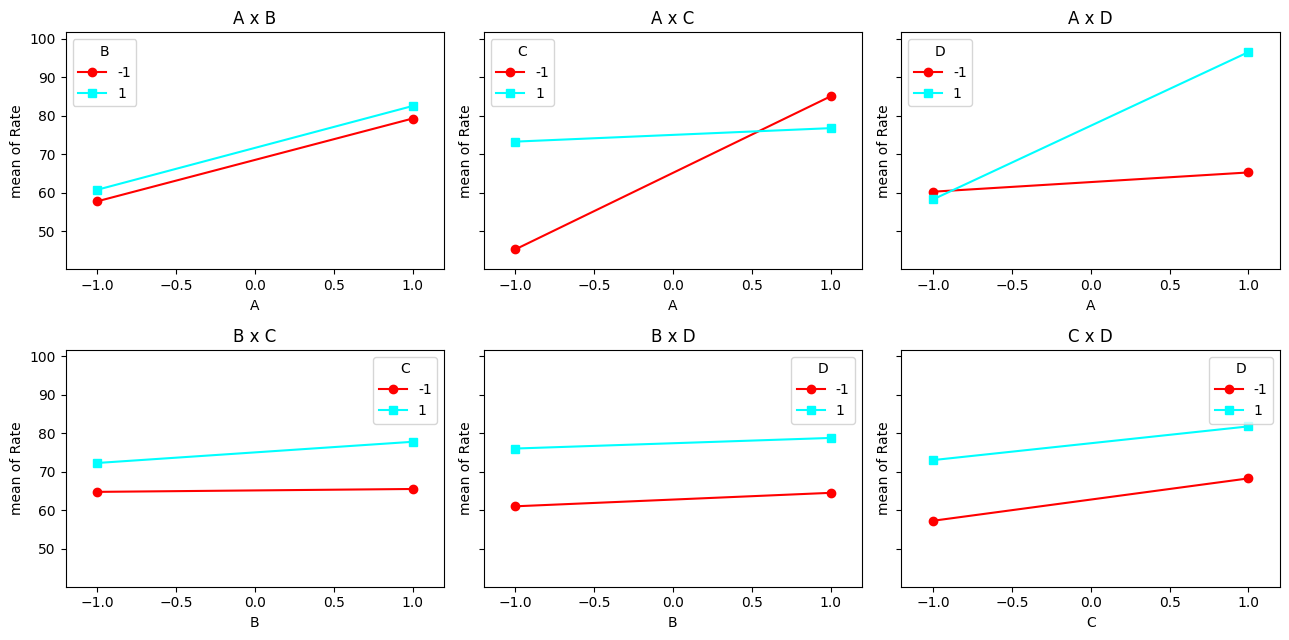

In [115]:
fig, axes = plt.subplots(1, 4, figsize=(13, 3), sharey=True)
for ax, f in zip(axes, factors):
    m = rate.groupby(f)["Rate"].mean()
    ax.plot(m.index, m.to_numpy(), "o-")
    ax.set(xticks=[-1, 1], xlabel=f, title=f"Main effect of {f}")
axes[0].set_ylabel("mean filtration rate")
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(2, 3, figsize=(13, 6.5), sharey=True)
for ax, (f1, f2) in zip(axes.flat, itertools.combinations(factors, 2)):
    interaction_plot(rate[f1], rate[f2], rate["Rate"], ax=ax, markers=["o", "s"])
    ax.set_title(f"{f1} x {f2}")
plt.tight_layout()
plt.show()

The plots suggest large main effects of $A$, $C$, $D$ and interactions $A \times C$ and $A \times D$. The lines of $B$ are
almost flat. But without an error estimate we cannot say which differences are larger than the noise.

### The full model has no error term

In [116]:
import warnings

full = smf.ols("Rate ~ A*B*C*D", data=rate).fit()
print("residual degrees of freedom:", full.df_resid)
with warnings.catch_warnings():
    warnings.simplefilter("ignore", RuntimeWarning)     # division by the zero residual df
    print(anova_lm(full).round(2))

residual degrees of freedom: 0.0
           df   sum_sq  mean_sq    F  PR(>F)
A         1.0  1870.56  1870.56  0.0     NaN
B         1.0    39.06    39.06  0.0     NaN
A:B       1.0     0.06     0.06  0.0     NaN
C         1.0   390.06   390.06  0.0     NaN
A:C       1.0  1314.06  1314.06  0.0     NaN
B:C       1.0    22.56    22.56  0.0     NaN
A:B:C     1.0    14.06    14.06  0.0     NaN
D         1.0   855.56   855.56  0.0     NaN
A:D       1.0  1105.56  1105.56  0.0     NaN
B:D       1.0     0.56     0.56  0.0     NaN
A:B:D     1.0    68.06    68.06  0.0     NaN
C:D       1.0     5.06     5.06  0.0     NaN
A:C:D     1.0    10.56    10.56  0.0     NaN
B:C:D     1.0    27.56    27.56  0.0     NaN
A:B:C:D   1.0     7.56     7.56  0.0     NaN
Residual  0.0     0.00      inf  NaN     NaN


16 observations, 16 parameters, 0 residual degrees of freedom. The sums of squares are correct, but **statsmodels prints
$F = 0$ and missing $p$-values: these are not test results.** We have to judge the effects without an estimate of $\sigma^2$.

### Effects from the table of signs

In [117]:
eff_table = effects_2k(rate, "Rate", factors)
eff = eff_table["effect"].rename(lambda t: t.replace(":", ""))      # names A, B, AB, ..., ABCD
eff_table.round(3)

,contrast,effect,SS,coef
term,,,,
A,173,21.625,1870.562,10.812
B,25,3.125,39.062,1.562
A:B,1,0.125,0.062,0.062
C,79,9.875,390.062,4.938
A:C,-145,-18.125,1314.062,-9.062
B:C,19,2.375,22.562,1.188
A:B:C,15,1.875,14.062,0.938
D,117,14.625,855.562,7.312
A:D,133,16.625,1105.562,8.312


In [118]:
# the effects are twice the regression coefficients of the full model
check = 2 * full.params.drop("Intercept")
np.allclose(check[eff_table.index], eff_table["effect"])

True

### Normal and half-normal plots of the effects

A negligible effect is $N(0, 4\sigma^2/N)$; the negligible effects lie on a straight line, the active effects are outliers.

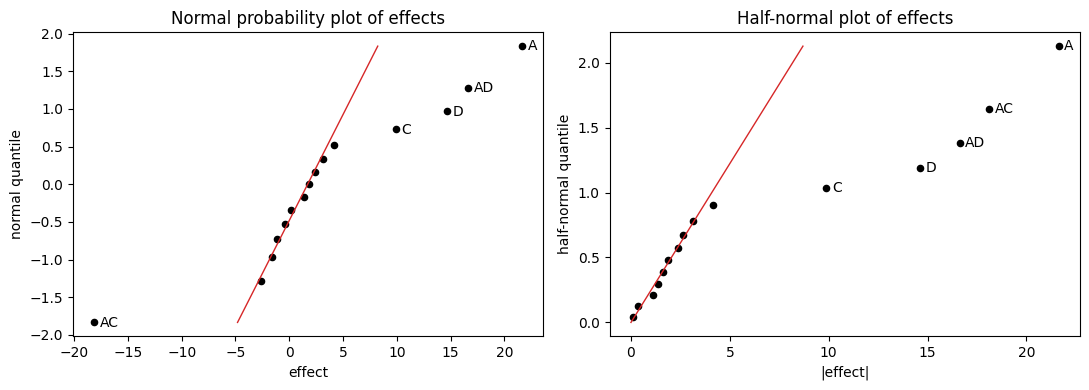

In [119]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
effect_plot(eff, ax=axes[0])
effect_plot(eff, half=True, ax=axes[1])
plt.tight_layout()
plt.show()

### Lenth's method and the Pareto plot

{'s0': np.float64(3.938), 'PSE': np.float64(2.625), 'ME': np.float64(6.748), 'SME': np.float64(13.699)}
|effect| > ME:  ['A', 'C', 'AC', 'D', 'AD']
|effect| > SME: ['A', 'AC', 'D', 'AD']


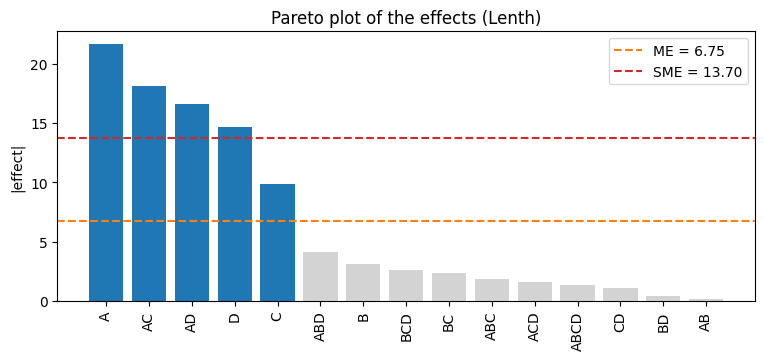

In [120]:
L = lenth(eff)
print({k: round(v, 3) for k, v in L.items()})
print("|effect| > ME: ", list(eff[eff.abs() > L["ME"]].index))
print("|effect| > SME:", list(eff[eff.abs() > L["SME"]].index))
pareto_plot(eff)
plt.show()

$PSE = 2.625$, $ME = 6.75$, $SME = 13.70$ (the same numbers as Montgomery). The effects $A$, $AC$, $AD$, $D$ exceed $SME$,
$C$ exceeds only $ME$. Because $AC$ is clearly active, we keep $C$ (hierarchy). The tentative model is
$A + C + D + AC + AD$; factor $B$ (pressure) does not appear at all.

### Projection into a replicated $2^3$ design

Dropping $B$ projects the single replicate of the $2^4$ into a $2^3$ design in $A$, $C$, $D$ with two replicates, so now
we have 8 degrees of freedom for pure error. (Last year's notebook built this design by stacking two copies of the $2^3$
table and pairing them with the observations in the wrong order. Fitting the model to the original data frame without $B$
avoids that mistake.)

In [121]:
m_acd = smf.ols("Rate ~ A*C*D", data=rate).fit()
anova_lm(m_acd)

,df,sum_sq,mean_sq,F,PR(>F)
A,1.0,1870.5625,1870.5625,83.367688,0.000017
C,1.0,390.0625,390.0625,17.384401,0.003124
A:C,1.0,1314.0625,1314.0625,58.565460,0.000060
D,1.0,855.5625,855.5625,38.130919,0.000267
A:D,1.0,1105.5625,1105.5625,49.272981,0.000110
C:D,1.0,5.0625,5.0625,0.225627,0.647483
A:C:D,1.0,10.5625,10.5625,0.470752,0.512032
Residual,8.0,179.5000,22.4375,NaN,NaN


In [122]:
final = smf.ols("Rate ~ A + C + D + A:C + A:D", data=rate).fit()
print(anova_lm(final).round(4))
print(final.summary().tables[1])
print(f"s = {np.sqrt(final.scale):.3f}, R2 = {final.rsquared:.4f}, R2_adj = {final.rsquared_adj:.4f}")

            df     sum_sq    mean_sq        F  PR(>F)
A          1.0  1870.5625  1870.5625  95.8648  0.0000
C          1.0   390.0625   390.0625  19.9904  0.0012
D          1.0   855.5625   855.5625  43.8469  0.0001
A:C        1.0  1314.0625  1314.0625  67.3447  0.0000
A:D        1.0  1105.5625  1105.5625  56.6592  0.0000
Residual  10.0   195.1250    19.5125      NaN     NaN
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept     70.0625      1.104     63.444      0.000      67.602      72.523
A             10.8125      1.104      9.791      0.000       8.352      13.273
C              4.9375      1.104      4.471      0.001       2.477       7.398
D              7.3125      1.104      6.622      0.000       4.852       9.773
A:C           -9.0625      1.104     -8.206      0.000     -11.523      -6.602
A:D            8.3125      1.104      7.527      0.000       5.852   

$$\hat y = 70.06 + 10.81\,x_1 + 4.94\,x_3 + 7.31\,x_4 - 9.06\,x_1x_3 + 8.31\,x_1x_4,$$
with $\hat\sigma = 4.42$ and $R^2 = 0.966$. The residual mean square 19.51 (10 df) is the pure error (8 df) plus the dropped
$CD$ and $ACD$ (2 df). Check the residuals, also against the dropped factor $B$:

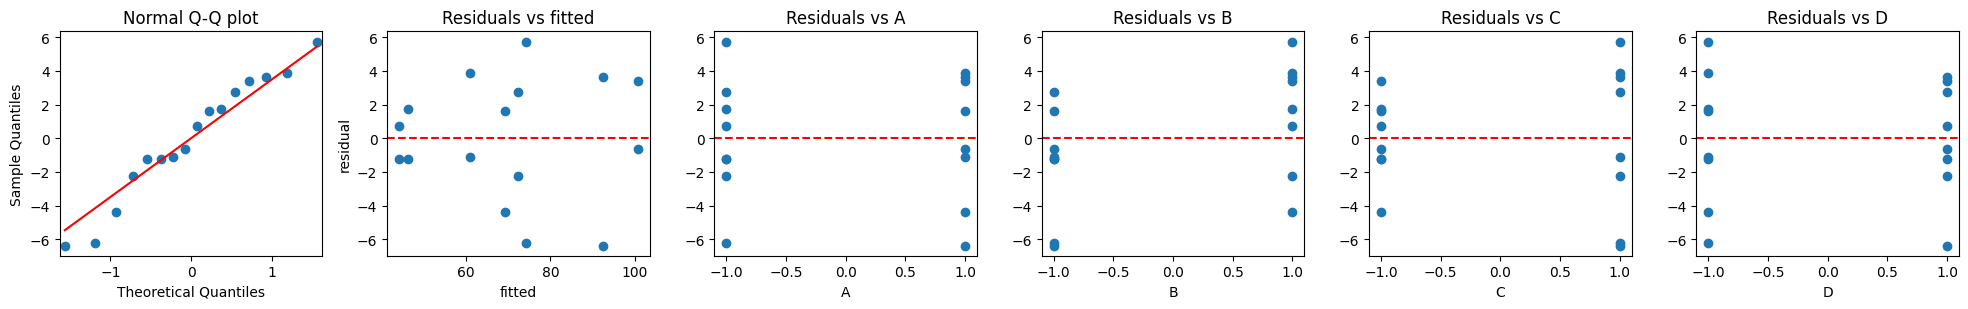

Shapiro-Wilk on residuals: ShapiroResult(statistic=np.float64(0.9534713000836792), pvalue=np.float64(0.5465944384429786))


In [123]:
residual_plots(final, rate, factors)

### Contour plots and the best settings

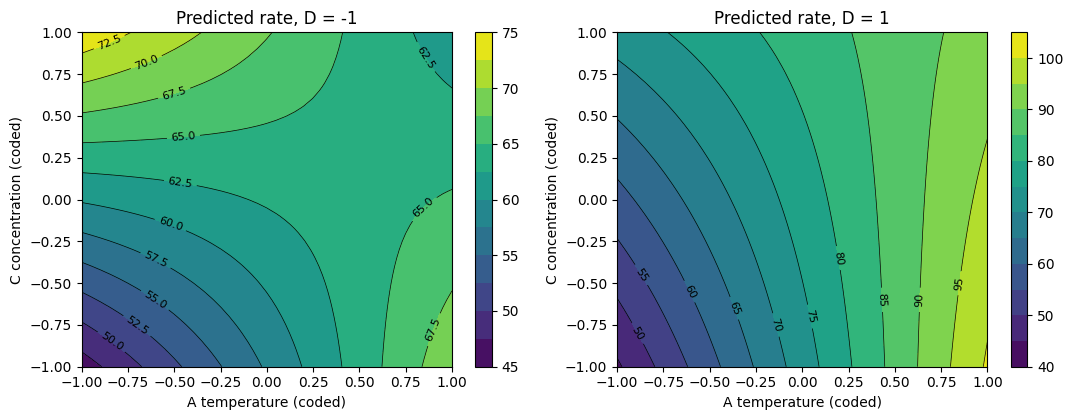

,A,C,D,predicted
5,1,-1,1,100.625
7,1,1,1,92.375
2,-1,1,-1,74.250


In [124]:
g = np.linspace(-1, 1, 41)
A, C = np.meshgrid(g, g)
fig, axes = plt.subplots(1, 2, figsize=(11, 4.3))
for ax, d in zip(axes, [-1, 1]):
    grid = pd.DataFrame({"A": A.ravel(), "C": C.ravel(), "D": d})
    Z = final.predict(grid).to_numpy().reshape(A.shape)
    cs = ax.contourf(A, C, Z, levels=12, cmap="viridis")
    ax.clabel(ax.contour(A, C, Z, levels=12, colors="k", linewidths=0.5), fontsize=8)
    fig.colorbar(cs, ax=ax)
    ax.set(xlabel="A temperature (coded)", ylabel="C concentration (coded)", title=f"Predicted rate, D = {d}")
plt.tight_layout()
plt.show()

corners = pd.DataFrame(list(itertools.product([-1, 1], repeat=3)), columns=["A", "C", "D"])
corners["predicted"] = final.predict(corners)
corners.sort_values("predicted", ascending=False).head(3)

The highest predicted filtration rate (100.6 gal/h) is at high temperature, low concentration of formaldehyde and high
stirring rate ($A = +$, $C = -$, $D = +$); pressure ($B$) can be set at the cheaper level. The model is linear with
interactions and should not be extrapolated outside the cube.

### Pooling only the highest-order interaction?

In [125]:
m_3way = smf.ols("Rate ~ (A + B + C + D)**3", data=rate).fit()
anova_lm(m_3way).round(4)

,df,sum_sq,mean_sq,F,PR(>F)
A,1.0,1870.5625,1870.5625,247.3471,0.0404
B,1.0,39.0625,39.0625,5.1653,0.2639
C,1.0,390.0625,390.0625,51.5785,0.0881
D,1.0,855.5625,855.5625,113.1322,0.0597
A:B,1.0,0.0625,0.0625,0.0083,0.9423
A:C,1.0,1314.0625,1314.0625,173.7603,0.0482
A:D,1.0,1105.5625,1105.5625,146.1901,0.0525
B:C,1.0,22.5625,22.5625,2.9835,0.3341
B:D,1.0,0.5625,0.5625,0.0744,0.8305
C:D,1.0,5.0625,5.0625,0.6694,0.5635


The error term is $ABCD$ with **one** degree of freedom, $F_{0.05,1,1} = 161.4$: even the large effects $C$, $D$ and
$AD$ are not significant. Such a test has almost no power; the normal plot / Lenth's method and the projection are better.

### The effect of an outlier

Suppose the run $cd$ was recorded as 375 instead of 75 (Montgomery, Section 6.5). The error of 300 enters every effect with
weight $\pm 300/8 = \pm 37.5$.

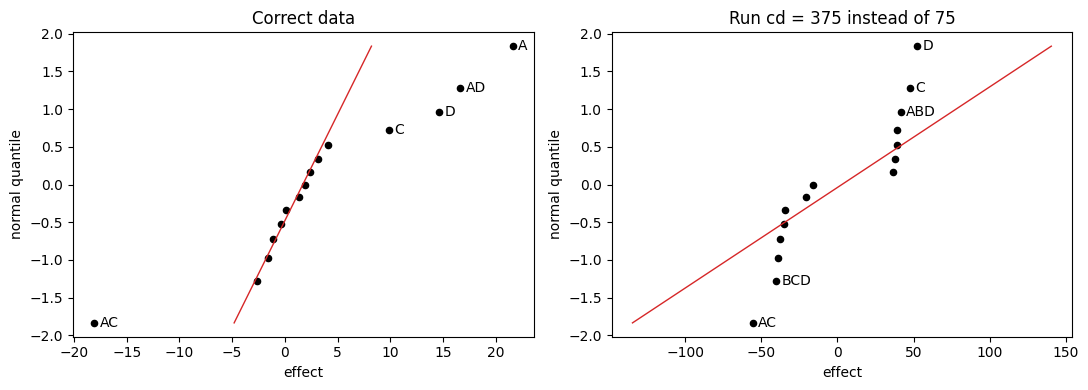

Lenth with the outlier: {'s0': np.float64(58.31), 'PSE': np.float64(58.31), 'ME': np.float64(149.9), 'SME': np.float64(304.31)}


In [126]:
bad = rate.copy()
bad.loc[bad["label"] == "cd", "Rate"] = 375
eff_bad = effects_2k(bad, "Rate", factors)["effect"].rename(lambda t: t.replace(":", ""))
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
effect_plot(eff, ax=axes[0], title="Correct data")
effect_plot(eff_bad, ax=axes[1], title="Run cd = 375 instead of 75")
plt.tight_layout()
plt.show()
print("Lenth with the outlier:", {k: round(v, 2) for k, v in lenth(eff_bad).items()})

The effects split into two groups around $\pm 37.5$ with a gap in the middle; there is no straight line through the small
effects and Lenth's method finds nothing. When the normal plot looks like this, check the data first.

----

## 2. Lecture example: data transformation (drill advance rate)

Montgomery, Example 6.3 (Daniel, 1976): a single replicate of a $2^4$ design for the advance rate of a drill. Factors: drill
load ($A$), flow rate ($B$), rotational speed ($C$) and type of drilling mud ($D$). The data are read from Figure 6.19 of the
book and entered in standard order.

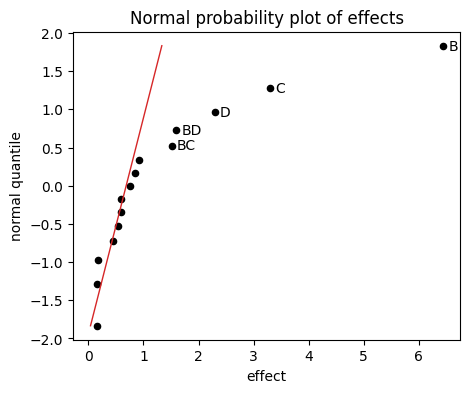

,effect
term,
AC,0.155
ABC,0.163
BCD,0.175
CD,0.448
ABCD,0.543
ACD,0.585
AB,0.590
ABD,0.760
AD,0.838


In [127]:
drill = pd.DataFrame([r[::-1] for r in itertools.product([-1, 1], repeat=4)], columns=factors)
drill["rate"] = [1.68, 1.98, 4.98, 5.70, 3.24, 3.44, 9.97, 9.07,
                 2.07, 2.44, 7.77, 9.43, 4.09, 4.53, 11.75, 16.30]
eff_drill = effects_2k(drill, "rate", factors)["effect"].rename(lambda t: t.replace(":", ""))
effect_plot(eff_drill)
plt.show()
eff_drill.sort_values().round(3)

On the original scale $B$, $C$, $D$ and the interactions $BC$, $BD$ look active. Fit this model and look at the residuals:

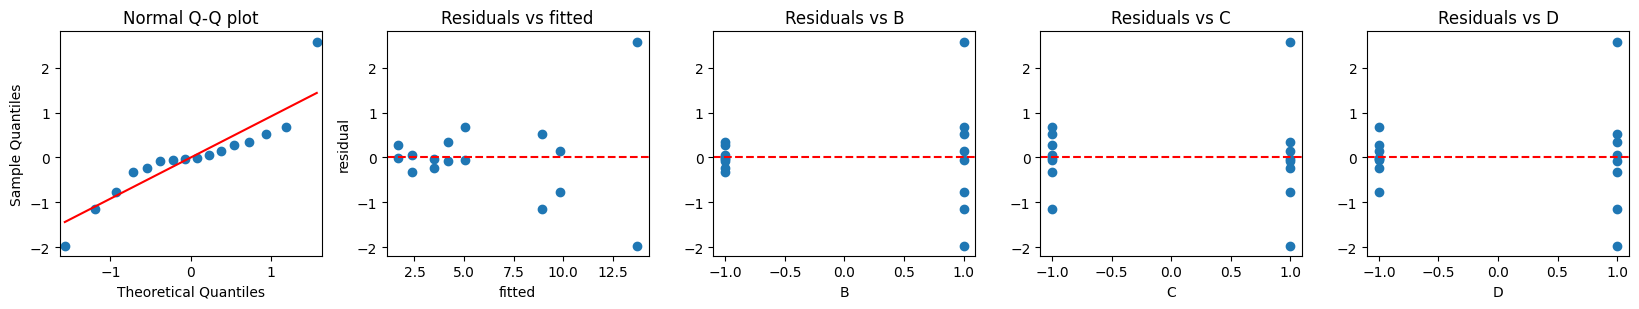

Shapiro-Wilk on residuals: ShapiroResult(statistic=np.float64(0.8811859330110848), pvalue=np.float64(0.04049249370392219))


In [128]:
m_raw = smf.ols("rate ~ B + C + D + B:C + B:D", data=drill).fit()
residual_plots(m_raw, drill, ["B", "C", "D"])

The residuals form a **funnel**: their spread grows with the predicted advance rate. The response is a rate, the effects are
likely multiplicative, so try the log transformation. A quick Box-Cox check: residual sum of squares of the model $B + C + D$
for the scaled power transformation $y^{(\lambda)} = (y^\lambda - 1)/(\lambda \dot y^{\lambda - 1})$ ($\dot y$ = geometric
mean, $\lambda = 0$: $\dot y \ln y$), so that the values are comparable across $\lambda$.

In [129]:
gm = np.exp(np.log(drill["rate"]).mean())
for lam in [1, 0.5, 0, -0.5, -1]:
    if lam == 0:
        y_lam = gm * np.log(drill["rate"])
    else:
        y_lam = (drill["rate"]**lam - 1) / (lam * gm**(lam - 1))
    ssr = smf.ols("y ~ B + C + D", data=drill.assign(y=y_lam)).fit().ssr
    print(f"lambda = {lam:5.1f}: residual SS = {ssr:6.2f}")

lambda =   1.0: residual SS =  32.81
lambda =   0.5: residual SS =  10.55
lambda =   0.0: residual SS =   4.21
lambda =  -0.5: residual SS =   7.87
lambda =  -1.0: residual SS =  23.26


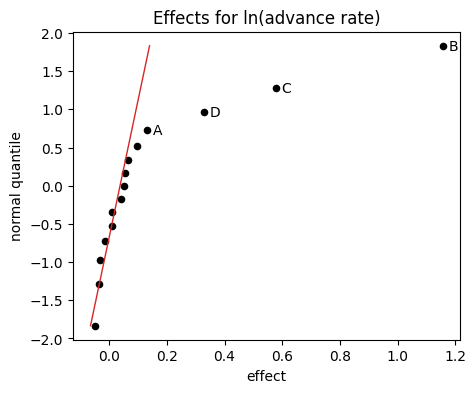

            df  sum_sq  mean_sq         F  PR(>F)
B          1.0  5.3452   5.3452  371.4928  0.0000
C          1.0  1.3389   1.3389   93.0517  0.0000
D          1.0  0.4305   0.4305   29.9224  0.0001
Residual  12.0  0.1727   0.0144       NaN     NaN
R2 = 0.9763


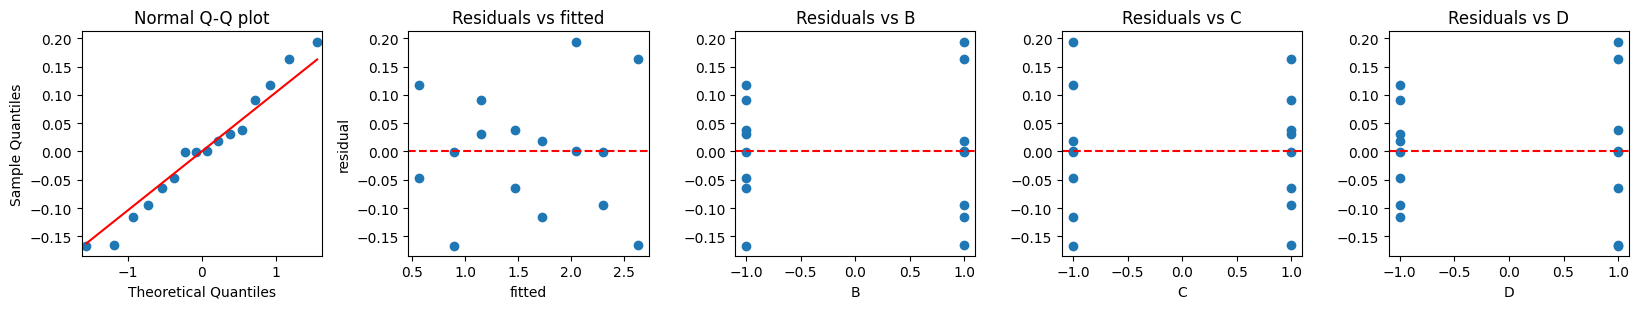

Shapiro-Wilk on residuals: ShapiroResult(statistic=np.float64(0.9681448902399934), pvalue=np.float64(0.8077359505482558))


In [130]:
drill["log_rate"] = np.log(drill["rate"])
eff_log = effects_2k(drill, "log_rate", factors)["effect"].rename(lambda t: t.replace(":", ""))
effect_plot(eff_log, n_label=4, title="Effects for ln(advance rate)")
plt.show()

m_log = smf.ols("log_rate ~ B + C + D", data=drill).fit()
print(anova_lm(m_log).round(4))
print(f"R2 = {m_log.rsquared:.4f}")
residual_plots(m_log, drill, ["B", "C", "D"])

After the log transformation only the main effects $B$, $C$, $D$ are active, the interactions disappeared and the residuals
look fine ($R^2 = 0.976$). Predictions are computed on the log scale and transformed back with `np.exp` (this estimates
the median of the advance rate):

In [131]:
new = pd.DataFrame({"B": [1], "C": [1], "D": [1]})
print("predicted advance rate at B = C = D = +1:", np.exp(m_log.predict(new)).round(2).iloc[0])

predicted advance rate at B = C = D = +1: 13.85


----

## 3. Lecture example: location and dispersion effects (panel process)

Montgomery, Example 6.4: a single replicate of a $2^4$ design in a process producing interior panels for aircraft. Response:
the average number of defects per panel in a press load. Factors: temperature $A$ (295, 325 $^\circ$F), clamp time $B$
(7, 9 min), resin flow $C$ (10, 20), closing time $D$ (15, 30 s). Data from Figure 6.26 of the book, in standard order.

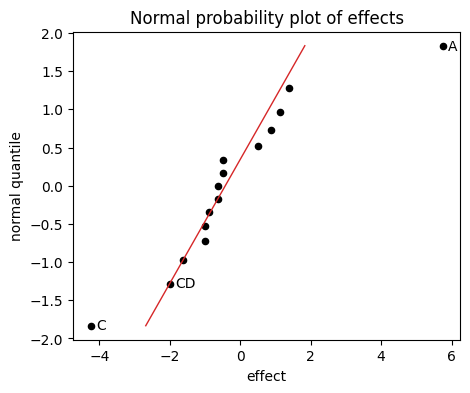

Intercept    6.688
A            2.875
C           -2.125
dtype: float64 R2 = 0.775


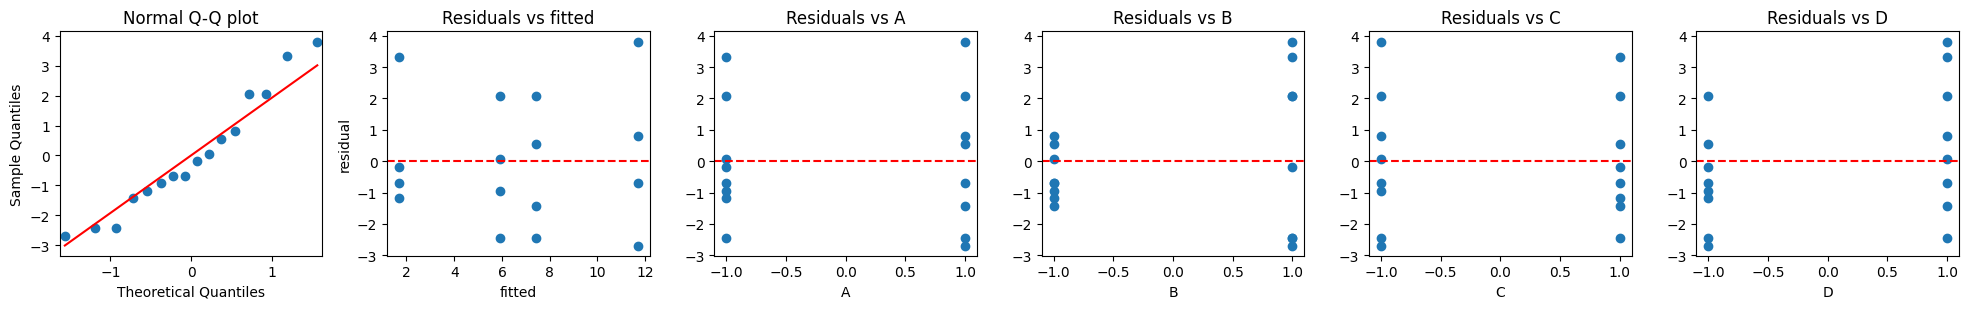

Shapiro-Wilk on residuals: ShapiroResult(statistic=np.float64(0.9427968214827391), pvalue=np.float64(0.3846952932748475))


In [132]:
panel = pd.DataFrame([r[::-1] for r in itertools.product([-1, 1], repeat=4)], columns=factors)
panel["defects"] = [5, 11, 3.5, 9, 0.5, 8, 1.5, 9.5, 6, 12.5, 8, 15.5, 1, 6, 5, 5]
eff_panel = effects_2k(panel, "defects", factors)["effect"].rename(lambda t: t.replace(":", ""))
effect_plot(eff_panel, n_label=3)
plt.show()

m_loc = smf.ols("defects ~ A + C", data=panel).fit()
print(m_loc.params.round(3), f"R2 = {m_loc.rsquared:.3f}")
residual_plots(m_loc, panel, factors)

Location effects: $A = 5.75$ and $C = -4.25$, so low temperature and high resin flow reduce the number of defects. The plot
of the residuals against $B$ (clamp time) shows a much larger spread at the high level of $B$. For every column of the table
of signs we compute the **dispersion effect**
$$F_i^* = \ln \frac{S^2(i^+)}{S^2(i^-)},$$
where $S(i^\pm)$ is the standard deviation of the residuals at the runs where the column is $\pm$.

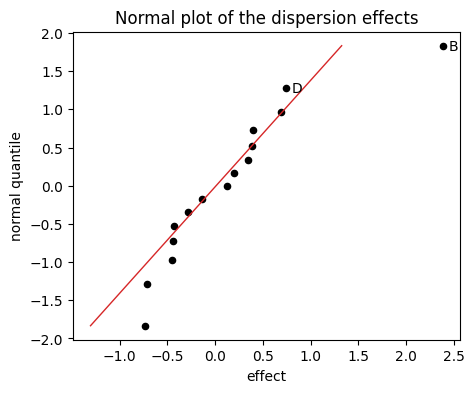

,0
ABCD,-0.74
ACD,-0.71
BC,-0.45
ABC,-0.44
AC,-0.43
C,-0.29
ABD,-0.14
AD,0.13
BCD,0.20
AB,0.35


In [133]:
e = m_loc.resid
Fstar = {}
for t in eff_panel.index:
    s = panel[list(t)].prod(axis=1)
    Fstar[t] = np.log(e[s == 1].var() / e[s == -1].var())
Fstar = pd.Series(Fstar)
effect_plot(Fstar, n_label=2, title="Normal plot of the dispersion effects")
plt.show()
Fstar.sort_values().round(2)

$F_B^* = 2.39$ stands out: clamp time does not change the mean number of defects, but the low clamp time gives a smaller
variability. Recommended: low temperature and high resin flow (location), low clamp time (dispersion).

----

## Assignment

Work on the assignment in class (in pairs, if you like). Whatever you do not finish in class, finish at home as homework.

* Run the notebook above and make sure you understand each step.
* Solve the following problems from Montgomery, *Design and Analysis of Experiments* (8th edition): **6.17, 6.28 with 6.29,
  6.31 with 6.32 and 6.36**; Problem 6.30 is optional.
* Use the normal (or half-normal) plot of the effects together with Lenth's method to choose the model, respect the
  hierarchy, state the hypotheses, the test statistic, its $p$-value and your decision for the final model, check the
  residuals and end each problem with a conclusion in one or two sentences.
* Submit your solved notebook as a pull request into the `HW/` folder of the course repository, named
  `HW/01NAEX_Ex06_HW_<Surname>.ipynb` (see `HW/README.md`). **Deadline: Sunday 8 November 2026** (the next lecture is on
  9 November; Team Project 1 has the same deadline).

### Problem 6.17

An experimenter has run a single replicate of a $2^4$ design. The following effect estimates have been calculated:

| Effect | Estimate | Effect | Estimate | Effect | Estimate |
|---|---|---|---|---|---|
| $A$ | 76.95 | $AB$ | $-51.32$ | $ABC$ | $-2.82$ |
| $B$ | $-67.52$ | $AC$ | 11.69 | $ABD$ | $-6.50$ |
| $C$ | $-7.84$ | $AD$ | 9.78 | $ACD$ | 10.20 |
| $D$ | $-18.73$ | $BC$ | 20.78 | $BCD$ | $-7.98$ |
| | | $BD$ | 14.74 | $ABCD$ | $-6.25$ |
| | | $CD$ | 1.27 | | |

(a) Construct a normal probability plot of these effects.

(b) Identify a tentative model, based on the plot of the effects in part (a).

(c) (Added.) Apply Lenth's method. Does it lead to the same model?

**Solution:**

In [134]:
# Create a dictionary with the effect estimates from Problem 6.17
effect_estimates = {
    "A": 76.95,
    "B": -67.52,
    "C": -7.84,
    "D": -18.73,
    "AB": -51.32,
    "AC": 11.69,
    "AD": 9.78,
    "BC": 20.78,
    "BD": 14.74,
    "CD": 1.27,
    "ABC": -2.82,
    "ABD": -6.50,
    "ACD": 10.20,
    "BCD": -7.98,
    "ABCD": -6.25
}

# Convert to a pandas Series for easy analysis and plotting
eff_617 = pd.Series(effect_estimates)

# Create a DataFrame for display
df_617 = pd.DataFrame(eff_617, columns=["Estimate"])
df_617.index.name = "Effect"
display(df_617)

,Estimate
Effect,
A,76.95
B,-67.52
C,-7.84
D,-18.73
AB,-51.32
AC,11.69
AD,9.78
BC,20.78
BD,14.74


<Axes: title={'center': 'Normal probability plot of effects'}, xlabel='effect', ylabel='normal quantile'>

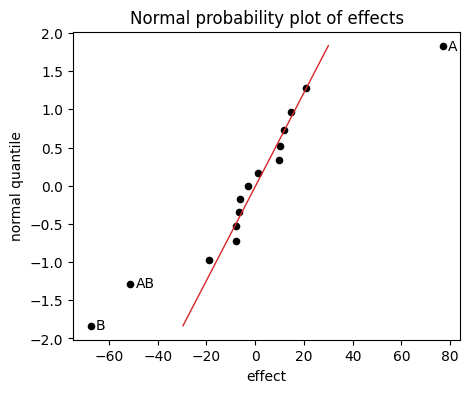

In [135]:
effect_plot(df_617["Estimate"], n_label=3)

Normal probability plot highlights the effect of variables $A,$ $B$ and their interaction while the effect of other variables and higher order interactions is negligible. Therefore, a tentative model looks like: $$\widehat{Y}=\hat\beta_0+38.475A-33.76B-25.66AB.$$ The intercept $\beta_0$, however, cannot be estimated, since we are not provided with the raw data.

{'s0': np.float64(15.3), 'PSE': np.float64(13.32), 'ME': np.float64(34.24), 'SME': np.float64(69.512)}
|effect| > ME:  ['A', 'B', 'AB']
|effect| > SME: ['A']


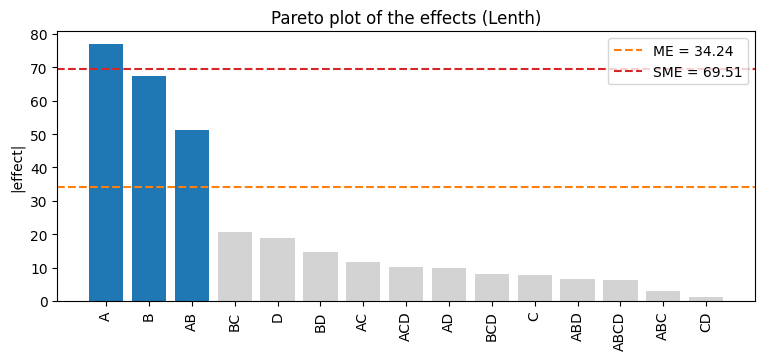

In [136]:
L = lenth(df_617['Estimate'])
print({k: round(v, 3) for k, v in L.items()})
print("|effect| > ME: ", list(df_617['Estimate'][df_617['Estimate'].abs() > L["ME"]].index))
print("|effect| > SME:", list(df_617['Estimate'][df_617['Estimate'].abs() > L["SME"]].index))
pareto_plot(df_617['Estimate'])
plt.show()

Findings of the Lenth's method (Pareto plot) are the same as these of the normal probability plot and would obviously lead to the identical model.

### Problems 6.28 and 6.29: process development (yield)

In a process development study on yield, four factors were studied, each at two levels: time ($A$: 2.5 and 3 h),
concentration ($B$: 14 and 18 %), pressure ($C$: 60 and 80 psi) and temperature ($D$: 225 and 250 $^\circ$C). A single
replicate of a $2^4$ design was run. The file `Problem_6_28.csv` contains the factor levels in natural units and the
yield (lbs) in standard order (the actual run order is given in Table P6.7 of the book).

In [137]:
p628 = pd.read_csv(URL + "Problem_6_28.csv")
p628

,Time,Concentration,Pressure,Temperature,Yield
0,2.5,14,60,225,12
1,3.0,14,60,225,18
2,2.5,18,60,225,13
3,3.0,18,60,225,16
4,2.5,14,80,225,17
5,3.0,14,80,225,15
6,2.5,18,80,225,20
7,3.0,18,80,225,15
8,2.5,14,60,250,10
9,3.0,14,60,250,25


**Problem 6.28**

(a) Construct a normal probability plot of the effect estimates. Which factors appear to have large effects?

(b) Conduct an analysis of variance using the normal probability plot in part (a) for guidance in forming an error term.
What are your conclusions?

(c) Write down a regression model relating yield to the important process variables.

(d) Analyze the residuals from this experiment. Does your analysis indicate any potential problems?

(e) Can this design be collapsed into a $2^3$ design with two replicates? If so, sketch the design with the average and range
of yield shown at each point in the cube. Interpret the results.

Hint: first code the factors to $-1$/$+1$, for example `np.where(p628["Time"] == 3, 1, -1)`.

**Solution:**

In [138]:
# Code the natural factors to -1 and +1
p628_coded = p628.copy()
p628_coded["A"] = np.where(p628["Time"] == 3.0, 1, -1)
p628_coded["B"] = np.where(p628["Concentration"] == 18, 1, -1)
p628_coded["C"] = np.where(p628["Pressure"] == 80, 1, -1)
p628_coded["D"] = np.where(p628["Temperature"] == 250, 1, -1)

# Compute all 2^k - 1 effects using the pre-defined helper function
eff_p628 = effects_2k(p628_coded, response="Yield", factors=list("ABCD"))
display(eff_p628.round(3))

,contrast,effect,SS,coef
term,,,,
A,36,4.50,81.00,2.250
B,4,0.50,1.00,0.250
A:B,-6,-0.75,2.25,-0.375
C,16,2.00,16.00,1.000
A:C,-34,-4.25,72.25,-2.125
B:C,2,0.25,0.25,0.125
A:B:C,8,1.00,4.00,0.500
D,26,3.25,42.25,1.625
A:D,32,4.00,64.00,2.000


<Axes: title={'center': 'Normal probability plot of effects'}, xlabel='effect', ylabel='normal quantile'>

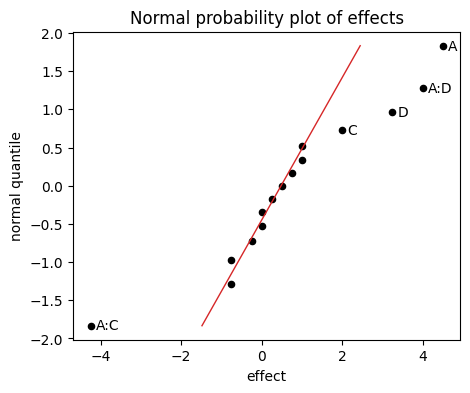

In [139]:
effect_plot(eff_p628['effect'])

From the normal probability plot we see that there are 5 factors with large effect, namely: Time $(A),$ Pressure $(C),$ Temperature $(D),$ and interactions $AC$ and $AD.$

In [171]:
m_acd_full = smf.ols("Yield ~ Time*Pressure*Temperature", data=p628).fit()
print('ANOVA table of the full model with variables Time (A), Pressure (C), Temperature(D):')
display(anova_lm(m_acd_full))
print('---------------------------------------------------------------------------------')
print('\nReduced model:')
m_acd = smf.ols("Yield ~ Time*Pressure*Temperature - Pressure:Temperature - Time:Pressure:Temperature", data=p628).fit()
print(m_acd.summary())
anova_lm(m_acd)

ANOVA table of the full model with variables Time (A), Pressure (C), Temperature(D):


,df,sum_sq,mean_sq,F,PR(>F)
Time,1.0,8.100000e+01,8.100000e+01,4.050000e+01,0.000217
Pressure,1.0,1.600000e+01,1.600000e+01,8.000000e+00,0.022204
Time:Pressure,1.0,7.225000e+01,7.225000e+01,3.612500e+01,0.000320
Temperature,1.0,4.225000e+01,4.225000e+01,2.112500e+01,0.001764
Time:Temperature,1.0,6.400000e+01,6.400000e+01,3.200000e+01,0.000478
Pressure:Temperature,1.0,6.108939e-27,6.108939e-27,3.054469e-27,1.000000
Time:Pressure:Temperature,1.0,2.500000e-01,2.500000e-01,1.250000e-01,0.732810
Residual,8.0,1.600000e+01,2.000000e+00,NaN,NaN


---------------------------------------------------------------------------------

Reduced model:
                            OLS Regression Results                            
Dep. Variable:                  Yield   R-squared:                       0.944
Model:                            OLS   Adj. R-squared:                  0.916
Method:                 Least Squares   F-statistic:                     33.91
Date:                Sun, 08 Nov 2026   Prob (F-statistic):           5.86e-06
Time:                        21:42:37   Log-Likelihood:                -22.827
No. Observations:                  16   AIC:                             57.65
Df Residuals:                      10   BIC:                             62.29
Df Model:                           5                                         
Covariance Type:            nonrobust                                         
                       coef    std err          t      P>|t|      [0.025      0.975]
---------------------------

,df,sum_sq,mean_sq,F,PR(>F)
Time,1.0,81.00,81.000,49.846154,0.000035
Pressure,1.0,16.00,16.000,9.846154,0.010549
Time:Pressure,1.0,72.25,72.250,44.461538,0.000056
Temperature,1.0,42.25,42.250,26.000000,0.000465
Time:Temperature,1.0,64.00,64.000,39.384615,0.000092
Residual,10.0,16.25,1.625,NaN,NaN


ANOVA tables confirm the conclusions which were made based on the normal probability plot. Final regression model for the yield ($Y$) looks like: $$\widehat{Y}=209.125-83.5A+2.4375C-1.63D-0.85AC+0.64CD.$$

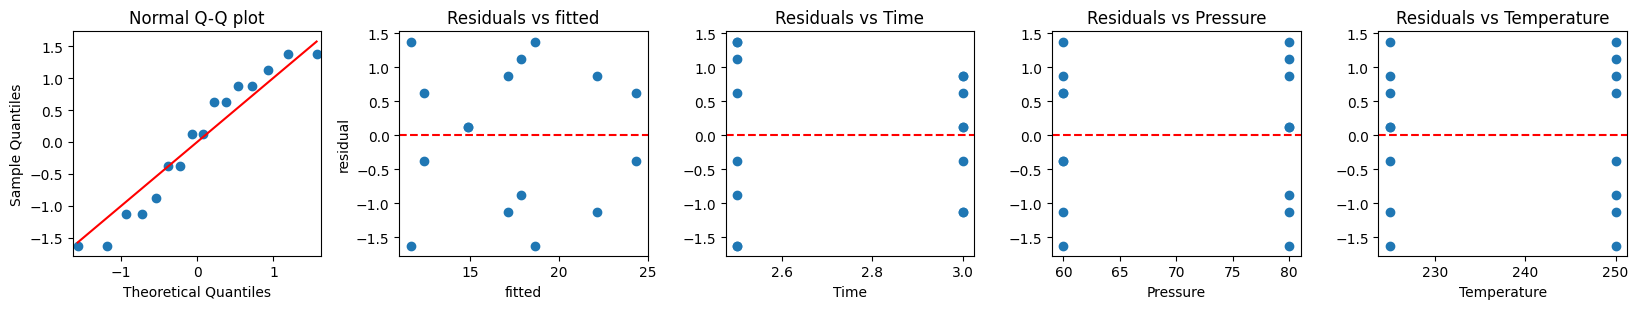

Shapiro-Wilk on residuals: ShapiroResult(statistic=np.float64(0.9226963060388462), pvalue=np.float64(0.18638769990831983))


In [141]:
residual_plots(m_acd, p628, ["Time", "Pressure", "Temperature"])

Residuals look OK and do not suggest any problems. Normality is also reasonable.

As we saw above, concentration ($B$) is left out from the model, so the design can be collapsed into a $2^3$ design with two replicates.

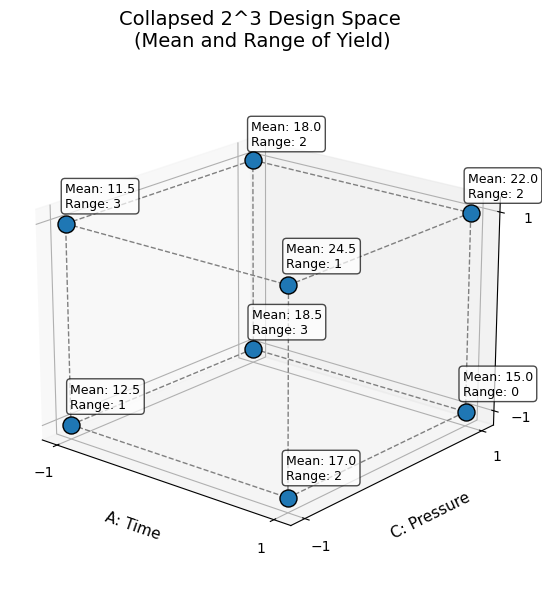

In [142]:
import itertools
import matplotlib.pyplot as plt

# Group by the active coded factors A (Time), C (Pressure), D (Temperature) to find mean and range
stats_3d = p628_coded.groupby(['A', 'C', 'D'])['Yield'].agg(['mean', lambda x: x.max() - x.min()]).reset_index()
stats_3d.columns = ['A', 'C', 'D', 'mean', 'range']

fig = plt.figure(figsize=(6, 6))
ax = fig.add_subplot(111, projection='3d')

# Draw the skeleton of the cube
for e in itertools.product([-1, 1], repeat=3):
    for j in range(3):
        if e[j] == -1:
            e2 = list(e)
            e2[j] = 1
            ax.plot(*zip(e, e2), color='gray', linestyle='--', lw=1)

# Plot vertices and annotate them with Mean and Range
for _, row in stats_3d.iterrows():
    ax.scatter(row['A'], row['C'], row['D'], color='tab:blue', s=150, edgecolor='black', zorder=5)
    # Label containing Mean and Range
    label_text = f"Mean: {row['mean']:.1f}\nRange: {row['range']:.0f}"
    # Position labels slightly offset from the points
    ax.text(row['A'] - 0.1, row['C'] + 0.1, row['D'] + 0.1, label_text, fontsize=9, bbox=dict(facecolor='white', alpha=0.7, boxstyle='round,pad=0.3'))

ax.set_xlabel('A: Time', fontsize=11)
ax.set_ylabel('C: Pressure', fontsize=11)
ax.set_zlabel('D: Temperature', fontsize=11)
ax.set_xticks([-1, 1])
ax.set_yticks([-1, 1])
ax.set_zticks([-1, 1])
ax.set_title('Collapsed 2^3 Design Space \n(Mean and Range of Yield)', fontsize=14, pad=20)
ax.view_init(elev=20, azim=-50)

plt.tight_layout()
plt.show()

Even though the effect of the concentration ($B$) was not detected by the normal probability plot, it can be seen that the two values in each corner are not identical, but still close to each other (range is $0-3$ in all corners). The biggest yield is achieved at the level of $3$ hours, $60$ psi and $250°C$.

**Problem 6.29.** Use the regression model in part (c) of Problem 6.28 to generate a response surface contour plot of yield.
Discuss the practical value of this response surface plot.

**Solution:**

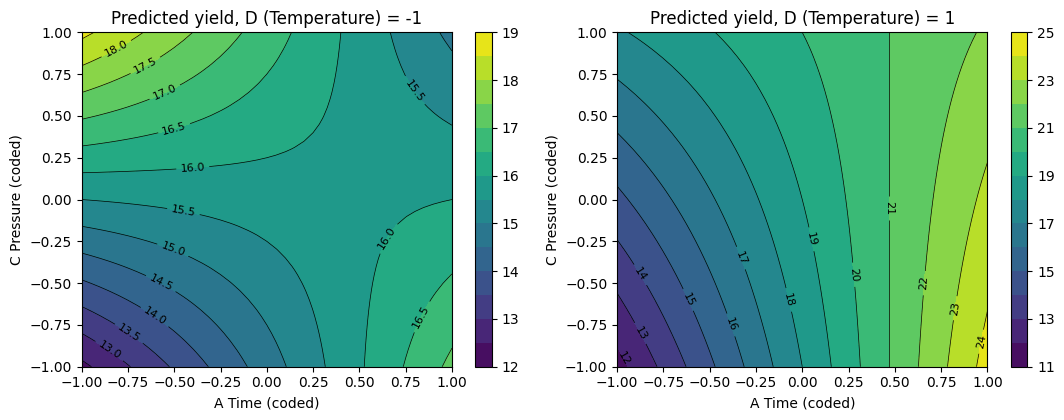

In [143]:
g = np.linspace(-1, 1, 41)
A, C = np.meshgrid(g, g)
fig, axes = plt.subplots(1, 2, figsize=(11, 4.3))

m_coded = smf.ols("Yield ~ A * C * D - C:D - A:C:D", data=p628_coded).fit()

for ax, d in zip(axes, [-1, 1]):
    grid = pd.DataFrame({"A": A.ravel(), "C": C.ravel(), "D": d})
    Z = m_coded.predict(grid).to_numpy().reshape(A.shape)
    cs = ax.contourf(A, C, Z, levels=12, cmap="viridis")
    ax.clabel(ax.contour(A, C, Z, levels=12, colors="k", linewidths=0.5), fontsize=8)
    fig.colorbar(cs, ax=ax)
    ax.set(xlabel="A Time (coded)", ylabel="C Pressure (coded)", title=f"Predicted yield, D (Temperature) = {d}")

plt.tight_layout()
plt.show()

Surface contour plots allow us to see at which conditions is the yield constant. It is extremely helpful when interactions are present. For each temperature level, it can be clearly seen in which direction we should adjust time and pressure to achieve bigger yield.

### Problems 6.31 and 6.32: a polymer (molecular weight and viscosity)

An experiment was conducted on a chemical process that produces a polymer. The four factors studied were temperature
($A$: 100 and 120 $^\circ$C), catalyst concentration ($B$: 4 and 8 %), time ($C$: 20 and 30 min) and pressure ($D$: 60 and
75 psi). Two responses, molecular weight and viscosity, were observed. The file `Problem_6_31.txt` contains the 16 runs of the
$2^4$ design in standard order followed by 4 center points.

**Use only the first 16 runs** (the factorial part). The center points and the test for curvature (part (b) of 6.31)
will come in Lecture 7.

In [144]:
p631 = pd.read_csv(URL + "Problem_6_31.txt", sep=";")
p631 = p631.iloc[:16].copy()          # the 2^4 runs only
p631

,Temperature,Concentration,Time,Pressure,Weight,Viscosity
0,100,4,20,60.0,2400,1400
1,120,4,20,60.0,2410,1500
2,100,8,20,60.0,2315,1520
3,120,8,20,60.0,2510,1630
4,100,4,30,60.0,2615,1380
5,120,4,30,60.0,2625,1525
6,100,8,30,60.0,2400,1500
7,120,8,30,60.0,2750,1620
8,100,4,20,75.0,2400,1400
9,120,4,20,75.0,2390,1525


**Problem 6.31**

(a) Consider only the molecular weight response. Plot the effect estimates on a normal probability scale. What effects
appear important?

(b) Use an analysis of variance to confirm the results from part (a).

(c) Write down a regression model to predict molecular weight as a function of the important variables.

(d) Analyze the residuals and comment on model adequacy.

(e) Repeat parts (a)-(d) using the viscosity response.

**Solution:**

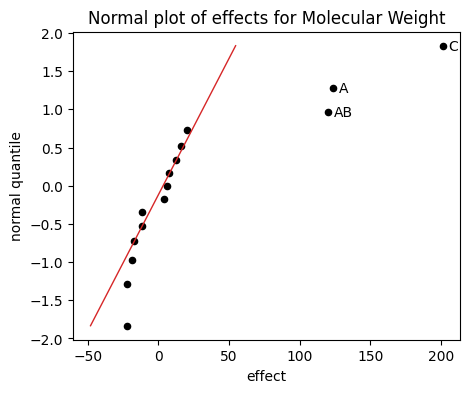

In [145]:
# Code the factors to -1 and +1 for Problem 6.31
p631_coded = p631.copy()
p631_coded["A"] = np.where(p631["Temperature"] == 120, 1, -1)
p631_coded["B"] = np.where(p631["Concentration"] == 8, 1, -1)
p631_coded["C"] = np.where(p631["Time"] == 30, 1, -1)
p631_coded["D"] = np.where(p631["Pressure"] == 75.0, 1, -1)

# Compute all 2^k - 1 effects using the pre-defined helper function for Molecular Weight
eff_weight = effects_2k(p631_coded, response="Weight", factors=list("ABCD"))

# Plot the effect estimates on a normal probability plot
eff_weight_series = eff_weight["effect"].rename(lambda t: t.replace(":", ""))
effect_plot(eff_weight_series, n_label=3, title="Normal plot of effects for Molecular Weight")
plt.show()

According to the normal plot major effects are: temperature ($A$), time ($C$) and the interaction of temperature and concentration ($AB$).

In [146]:
m_abc = smf.ols("Weight ~ A*B*C - A:C - A:B:C - B:C", data=p631_coded).fit()
print(m_abc.summary())
anova_lm(m_abc)

                            OLS Regression Results                            
Dep. Variable:                 Weight   R-squared:                       0.963
Model:                            OLS   Adj. R-squared:                  0.949
Method:                 Least Squares   F-statistic:                     70.95
Date:                Sun, 08 Nov 2026   Prob (F-statistic):           8.80e-08
Time:                        21:04:56   Log-Likelihood:                -74.899
No. Observations:                  16   AIC:                             159.8
Df Residuals:                      11   BIC:                             163.7
Df Model:                           4                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept   2506.2500      7.872    318.378      0.0

,df,sum_sq,mean_sq,F,PR(>F)
A,1.0,61256.25,61256.250000,61.782808,7.721183e-06
B,1.0,506.25,506.250000,0.510602,4.897653e-01
A:B,1.0,57600.00,57600.000000,58.095129,1.031806e-05
C,1.0,162006.25,162006.250000,163.398854,6.060089e-08
Residual,11.0,10906.25,991.477273,NaN,NaN


ANOVA table supports our findings. In spite of the large p-value ($0.489$), concentration ($B$) stays in the model to respect the hierarchy principle.

Regression model of molecular weight is: $\widehat{Y}=2506.25+61.875A-5.625B+100.625C+60AB.$

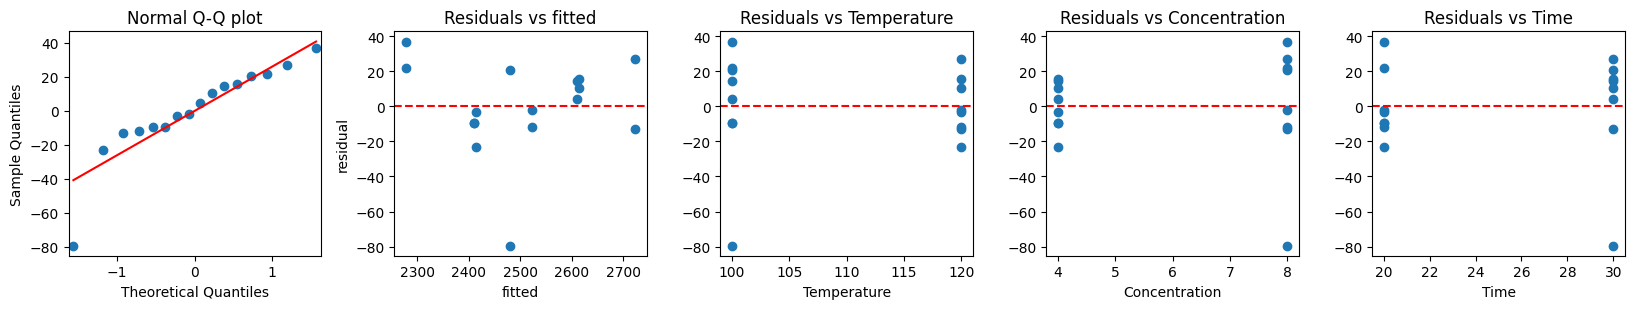

Shapiro-Wilk on residuals: ShapiroResult(statistic=np.float64(0.868067894397609), pvalue=np.float64(0.025409128758613796))


In [147]:
residual_plots(m_abc, p631, ["Temperature", "Concentration", "Time"])

One measurement ($100°C; 8\%; 30$ min; $60$ psi) is suspicious and breaks the assumption of normality. Other residuals look OK.

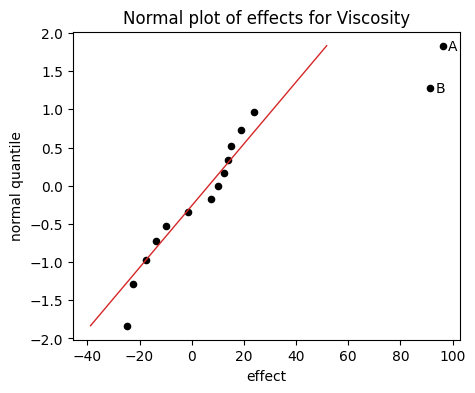

In [148]:
eff_viscosity = effects_2k(p631_coded, response="Viscosity", factors=list("ABCD"))

# Plot the effect estimates on a normal probability plot
eff_viscosity_series = eff_viscosity["effect"].rename(lambda t: t.replace(":", ""))
effect_plot(eff_viscosity_series, n_label=2, title="Normal plot of effects for Viscosity")
plt.show()

In [149]:
m_ab = smf.ols("Viscosity ~ A+B", data=p631_coded).fit()
print(m_ab.summary())
anova_lm(m_ab)

                            OLS Regression Results                            
Dep. Variable:              Viscosity   R-squared:                       0.839
Model:                            OLS   Adj. R-squared:                  0.814
Method:                 Least Squares   F-statistic:                     33.93
Date:                Sun, 08 Nov 2026   Prob (F-statistic):           6.93e-06
Time:                        21:04:56   Log-Likelihood:                -76.595
No. Observations:                  16   AIC:                             159.2
Df Residuals:                      13   BIC:                             161.5
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept   1500.6250      8.051    186.397      0.0

,df,sum_sq,mean_sq,F,PR(>F)
A,1.0,37056.25,37056.250000,35.733426,0.000046
B,1.0,33306.25,33306.250000,32.117293,0.000077
Residual,13.0,13481.25,1037.019231,NaN,NaN


Both ANOVA table and normal probability plot agree that viscosity can be modelled additively as a combination of temperature ($A$) and concentration ($B$): $$\widehat{Y}=1500.625+48.125A+45.625B.$$

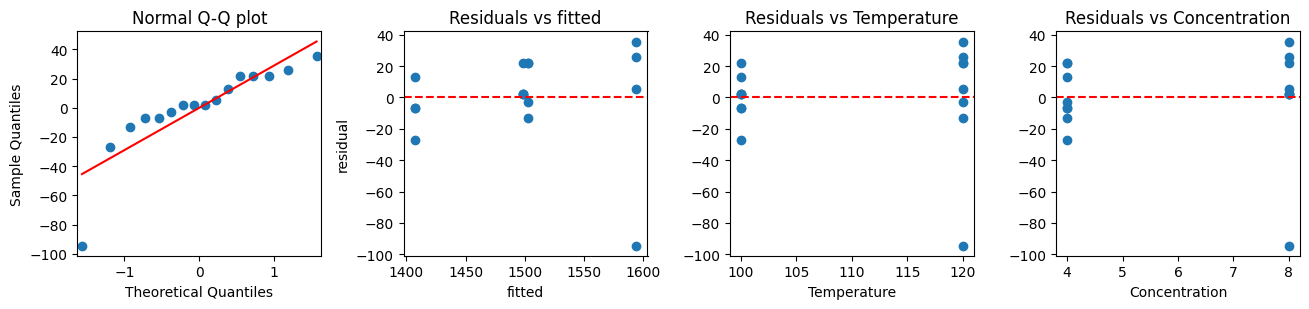

Shapiro-Wilk on residuals: ShapiroResult(statistic=np.float64(0.7933729462974481), pvalue=np.float64(0.002226960359649832))


In [150]:
residual_plots(m_ab, p631, ["Temperature", "Concentration"])

**Problem 6.32.** Use the regression models for molecular weight and viscosity to answer the following questions.

(a) Construct a response surface contour plot for molecular weight. In what direction would you adjust the process variables
to increase molecular weight?

(b) Construct a response surface contour plot for viscosity. In what direction would you adjust the process variables to
decrease viscosity?

(c) What operating conditions would you recommend if it was necessary to produce a product with molecular weight between
2400 and 2500 and the lowest possible viscosity?

**Solution:**

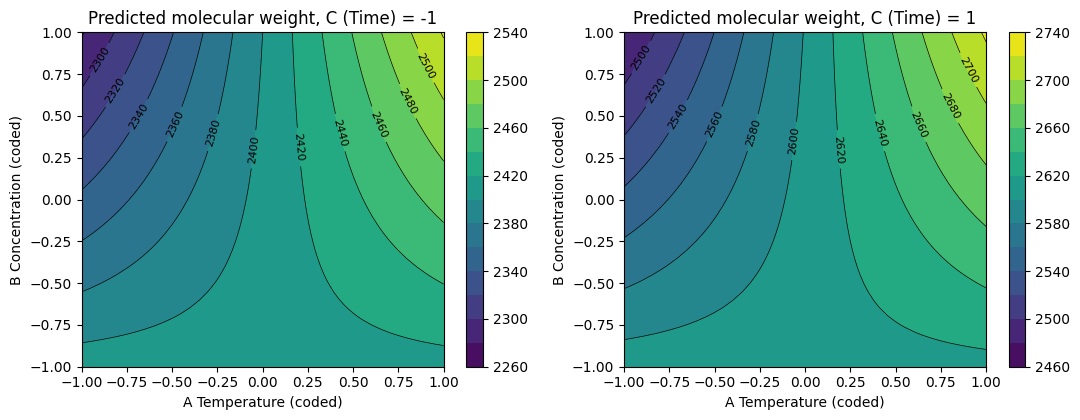

In [151]:
g = np.linspace(-1, 1, 41)
A, B = np.meshgrid(g, g)
fig, axes = plt.subplots(1, 2, figsize=(11, 4.3))

m_abc = smf.ols("Weight ~ A*B*C - A:C - A:B:C - B:C", data=p631_coded).fit()

for ax, c in zip(axes, [-1, 1]):
    grid = pd.DataFrame({"A": A.ravel(), "B": B.ravel(), "C": c})
    Z = m_abc.predict(grid).to_numpy().reshape(A.shape)
    cs = ax.contourf(A, B, Z, levels=12, cmap="viridis")
    ax.clabel(ax.contour(A, B, Z, levels=12, colors="k", linewidths=0.5), fontsize=8)
    fig.colorbar(cs, ax=ax)
    ax.set(xlabel="A Temperature (coded)", ylabel="B Concentration (coded)", title=f"Predicted molecular weight, C (Time) = {c}")

plt.tight_layout()
plt.show()

To maximize molecular weight, we should ideally set time to $30$ min and concentration to $8\%,$ then it can be claimed that with increasing temperature molecular weight also rises.

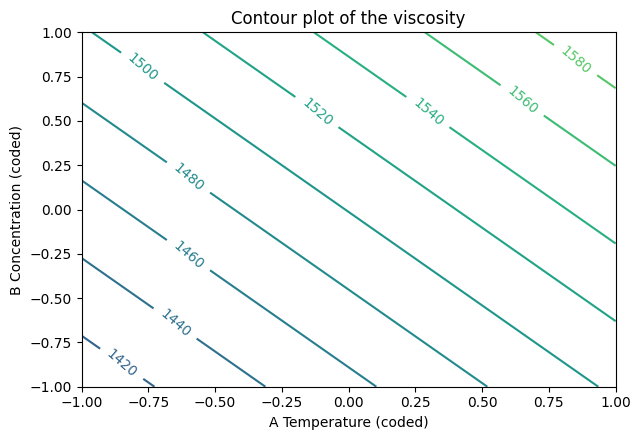

In [152]:
g1, g2 = np.meshgrid(np.linspace(-1, 1, 41), np.linspace(-1, 1, 41))
grid = pd.DataFrame({"A": g1.ravel(), "B": g2.ravel()})
z = m_ab.predict(grid).to_numpy().reshape(g1.shape)

fig = plt.figure(figsize=(12, 4.5))
ax2 = fig.add_subplot(1, 2, 2)
cs = ax2.contour(g1, g2, z, levels=np.arange(1300, 1700, 20), cmap="viridis")
ax2.clabel(cs, fmt="%.0f")
ax2.set(xlabel="A Temperature (coded)", ylabel="B Concentration (coded)", title="Contour plot of the viscosity")
plt.tight_layout(); plt.show()

Since no interaction is present in our model for viscosity, we would simply reach minimal viscosity by minimizing both temperature ($A$) and concentration ($B$).

To produce a product with molecular weight between
2400 and 2500 and the lowest possible viscosity, I would recommend to set all three variables temperature ($A$), concentration ($B$) and Time ($C$) to the lower level.

### Problem 6.36: resistivity of a silicon wafer

Resistivity on a silicon wafer is influenced by several factors. The results of a single replicate of a $2^4$ factorial
experiment performed during a critical processing step are (standard order):

In [153]:
p636 = pd.DataFrame([r[::-1] for r in itertools.product([-1, 1], repeat=4)], columns=list("ABCD"))
p636["resistivity"] = [1.92, 11.28, 1.09, 5.75, 2.13, 9.53, 1.03, 5.35,
                       1.60, 11.73, 1.16, 4.68, 2.16, 9.11, 1.07, 5.30]
p636

,A,B,C,D,resistivity
0,-1,-1,-1,-1,1.92
1,1,-1,-1,-1,11.28
2,-1,1,-1,-1,1.09
3,1,1,-1,-1,5.75
4,-1,-1,1,-1,2.13
5,1,-1,1,-1,9.53
6,-1,1,1,-1,1.03
7,1,1,1,-1,5.35
8,-1,-1,-1,1,1.60
9,1,-1,-1,1,11.73


**Problem 6.36**

(a) Estimate the factor effects. Plot the effect estimates on a normal probability plot and select a tentative model.

(b) Fit the model identified in part (a) and analyze the residuals. Is there any indication of model inadequacy?

(c) Repeat the analysis from parts (a) and (b) using $\ln(y)$ as the response variable. Is there an indication that the
transformation has been useful?

(d) Fit a model in terms of the coded variables that can be used to predict the resistivity.

**Solution:**

,contrast,effect,SS,coef
term,,,,
A,50.57,6.321,159.833,3.161
B,-24.03,-3.004,36.090,-1.502
A:B,-17.11,-2.139,18.297,-1.069
C,-3.53,-0.441,0.779,-0.221
A:C,-4.77,-0.596,1.422,-0.298
B:C,3.67,0.459,0.842,0.229
A:B:C,5.51,0.689,1.898,0.344
D,-1.27,-0.159,0.101,-0.079
A:D,-0.91,-0.114,0.052,-0.057


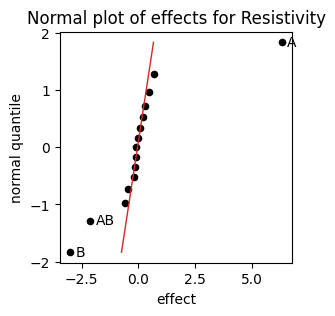

In [154]:
# Calculate all 2^k - 1 effects for the resistivity response in Problem 6.36
eff_p636 = effects_2k(p636, response="resistivity", factors=list("ABCD"))
display(eff_p636.round(3))

# Construct the normal probability plot of the effects
eff_p636_series = eff_p636["effect"].rename(lambda t: t.replace(":", ""))
fig, ax = plt.subplots(figsize=(3, 3))
effect_plot(eff_p636_series, n_label=3, ax=ax, title="Normal plot of effects for Resistivity")
plt.show()

The three largest effects are: $A$, $B$ and $AB$.

In [155]:
m_resist = smf.ols("resistivity ~ A * B", data=p636).fit()
print(m_resist.summary())

                            OLS Regression Results                            
Dep. Variable:            resistivity   R-squared:                       0.974
Model:                            OLS   Adj. R-squared:                  0.967
Method:                 Least Squares   F-statistic:                     148.8
Date:                Sun, 08 Nov 2026   Prob (F-statistic):           9.33e-10
Time:                        21:04:58   Log-Likelihood:                -14.527
No. Observations:                  16   AIC:                             37.05
Df Residuals:                      12   BIC:                             40.15
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept      4.6806      0.173     27.028      0.0

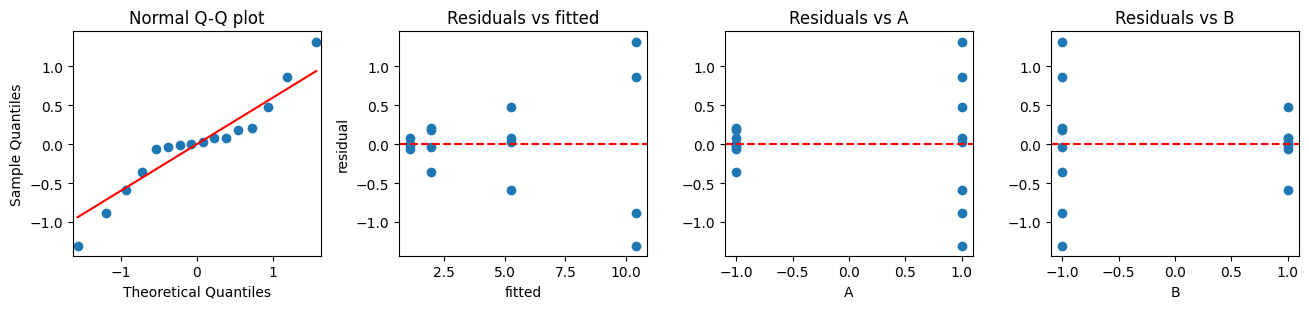

Shapiro-Wilk on residuals: ShapiroResult(statistic=np.float64(0.9428466534821187), pvalue=np.float64(0.3853569926239604))


In [156]:
residual_plots(m_resist, p636, ["A", "B"])

Even though the normality is not rejected based on the Shapiro-Wilk test ($p=0.385$), normal Q-Q plot is a bit wavy and residuals increase with increasing fitted values. Some transformation might help in this case.

,contrast,effect,SS,coef
term,,,,
A,13.006,1.626,10.572,0.813
B,-5.028,-0.629,1.580,-0.314
A:B,-0.395,-0.049,0.010,-0.025
C,-0.103,-0.013,0.001,-0.006
A:C,-0.636,-0.079,0.025,-0.040
B:C,-0.068,-0.008,0.000,-0.004
A:B:C,1.015,0.127,0.064,0.063
D,-0.289,-0.036,0.005,-0.018
A:D,-0.153,-0.019,0.001,-0.010


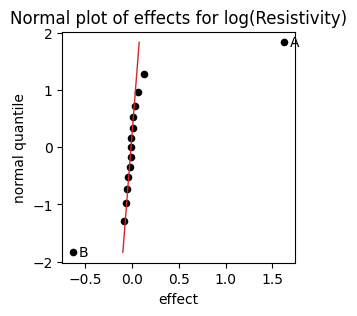

In [157]:
p636['ln_resistivity'] = np.log(p636['resistivity'])

eff_p636_ln = effects_2k(p636, response="ln_resistivity", factors=list("ABCD"))
display(eff_p636_ln.round(3))

# Construct the normal probability plot of the effects
eff_p636_series = eff_p636_ln["effect"].rename(lambda t: t.replace(":", ""))
fig, ax = plt.subplots(figsize=(3, 3))
effect_plot(eff_p636_series, n_label=2, ax=ax, title="Normal plot of effects for log(Resistivity)")
plt.show()

There is no need of interaction $AB$ in the model with logarithmically transformed response variable.

In [158]:
m_ln_resist = smf.ols("ln_resistivity ~ A + B", data=p636).fit()
print(m_ln_resist.summary())

                            OLS Regression Results                            
Dep. Variable:         ln_resistivity   R-squared:                       0.988
Model:                            OLS   Adj. R-squared:                  0.987
Method:                 Least Squares   F-statistic:                     553.4
Date:                Sun, 08 Nov 2026   Prob (F-statistic):           2.64e-13
Time:                        21:04:59   Log-Likelihood:                 15.052
No. Observations:                  16   AIC:                            -24.10
Df Residuals:                      13   BIC:                            -21.79
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept      1.1854      0.026     45.253      0.0

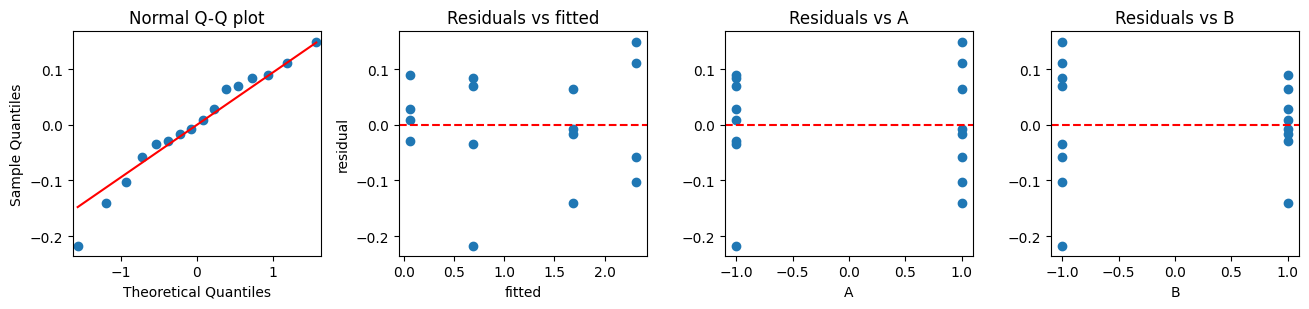

Shapiro-Wilk on residuals: ShapiroResult(statistic=np.float64(0.9667947125870828), pvalue=np.float64(0.7843979538937469))


In [159]:
residual_plots(m_ln_resist, p636, ["A", "B"])

Logarithmic transformation definitely helped, spread of residuals is more random.

### Problem 6.30 (optional): the scrumptious brownie experiment

The purpose of this experiment was to determine how the pan material ($A$: glass, aluminum), the stirring method
($B$: spoon, mixer) and the brand of brownie mix ($C$: expensive, cheap) affect the scrumptiousness of brownies, a subjective
measure from a questionnaire (taste, appearance, consistency, aroma, ...). An eight-person test panel sampled each batch and
filled out the questionnaire. Each row below is **one batch** of brownies; the 8 columns are the ratings of the 8 panel members.

In [160]:
brownie = pd.DataFrame([r[::-1] for r in itertools.product([-1, 1], repeat=3)], columns=list("ABC"))
ratings = [[11, 9, 10, 10, 11, 10, 8, 9],
           [15, 10, 16, 14, 12, 9, 6, 15],
           [9, 12, 11, 11, 11, 11, 11, 12],
           [16, 17, 15, 12, 13, 13, 11, 11],
           [10, 11, 15, 8, 6, 8, 9, 14],
           [12, 13, 14, 13, 9, 13, 14, 9],
           [10, 12, 13, 10, 7, 7, 17, 13],
           [15, 12, 15, 13, 12, 12, 9, 14]]
brownie = brownie.join(pd.DataFrame(ratings, columns=[f"taster{i}" for i in range(1, 9)]))
brownie

,A,B,C,taster1,taster2,taster3,taster4,taster5,taster6,taster7,taster8
0,-1,-1,-1,11,9,10,10,11,10,8,9
1,1,-1,-1,15,10,16,14,12,9,6,15
2,-1,1,-1,9,12,11,11,11,11,11,12
3,1,1,-1,16,17,15,12,13,13,11,11
4,-1,-1,1,10,11,15,8,6,8,9,14
5,1,-1,1,12,13,14,13,9,13,14,9
6,-1,1,1,10,12,13,10,7,7,17,13
7,1,1,1,15,12,15,13,12,12,9,14


**Problem 6.30 (optional)**

(a) Analyze the data from this experiment as if there were eight replicates of a $2^3$ design. Comment on the results.

(b) Is the analysis in part (a) the correct approach? There are only eight batches; do we really have eight replicates of a
$2^3$ factorial design?

(c) Analyze the average and standard deviation of the scrumptiousness ratings. Comment on the results. Is this analysis more
appropriate than the one in part (a)? Why or why not?

**Solution:**